# Equipment Condition Modelling with PySpark

**A reproducible synthetic telemetry pipeline for exploring service indicators**

This notebook processes daily readings from **250 fictional agricultural machines** over **30 operating days**. A redesigned generator produces vibration, temperature, and hydraulic-pressure measurements with shared workload fluctuations, machine-specific variation, and gradual wear-related trends. Each machine also receives a simulated binary maintenance label.

Apache Spark handles data inspection, quality filtering, time-window summaries, record integration, and a Random Forest classifier. The modelling workflow and its training settings are retained from the previous exercise, but the **data values, field definitions, and target labels are new**. Scores from earlier runs are not applicable to this dataset.

> All measurements and labels are synthetic. They are not engineering thresholds or a maintenance recommendation system.


In [1]:
# Start a local Spark session with the local CPU parallelism setting.
# The session is reused when an active Spark context already exists.
from pyspark.sql import SparkSession
from pyspark.sql.functions import col

spark = (
    SparkSession.builder
    .appName("MachineCondition_LocalSpark")
    .master("local[*]")
    .getOrCreate()
)

sc = spark.sparkContext

print("Spark version:", sc.version)
print("Spark master:", sc.master)
print("Default parallelism:", sc.defaultParallelism)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/04 17:23:35 WARN Utils: Your hostname, debianvm, resolves to a loopback address: 127.0.1.1; using 192.168.1.103 instead (on interface enp0s3)
26/11/04 17:23:35 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/04 17:23:36 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.3.0
Spark master: local[*]
Default parallelism: 16


## 1. Import and inspect daily operating signals

Read the generated sensor table into Spark, reproduce the four-partition loading pattern, and inspect the first records, schema, lineage, and row count. Run the notebook with the extracted project directory as its working directory so relative `data/` paths resolve.


In [2]:
# Load sensor history and establish four Spark-managed partitions.
telemetry_path = "data/machine_operating_signals.csv"

telemetry_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(telemetry_path)
)

# Keep processing inside Spark SQL instead of passing rows through Python workers.
telemetry_raw = telemetry_df.repartition(4)

print("Sensor-data partitions:",
      telemetry_raw.rdd.getNumPartitions())

telemetry_raw.show(5)

Sensor-data partitions: 4
+----------+-------------+-------------------+--------------------+----------------------+---------------------+
|machine_id|operating_day|motor_vibration_rms|engine_temperature_c|hydraulic_pressure_bar|diagnostic_event_code|
+----------+-------------+-------------------+--------------------+----------------------+---------------------+
|   EQ-0105|            2|               6.16|                94.9|                157.82|                    0|
|   EQ-0048|           30|               4.17|               90.04|                176.61|                    0|
|   EQ-0116|           14|               6.35|               91.12|                146.22|                    0|
|   EQ-0117|           11|               4.68|                80.2|                182.59|                    0|
|   EQ-0091|           10|               2.17|                77.3|                183.07|                    0|
+----------+-------------+-------------------+--------------------+---

In [3]:
# Inspect the RDD lineage used by the imported Spark table.
print(telemetry_raw.rdd.toDebugString().decode("utf-8"))

(4) MapPartitionsRDD[17] at javaToPython at DirectMethodHandleAccessor.java:103 []
 |  MapPartitionsRDD[16] at javaToPython at DirectMethodHandleAccessor.java:103 []
 |  SQLExecutionRDD[15] at javaToPython at DirectMethodHandleAccessor.java:103 []
 |  ShuffledRowRDD[14] at $anonfun$withThreadLocalCaptured$1 at CompletableFuture.java:1768 []
 +-(1) MapPartitionsRDD[13] at $anonfun$withThreadLocalCaptured$1 at CompletableFuture.java:1768 []
    |  MapPartitionsRDD[12] at $anonfun$withThreadLocalCaptured$1 at CompletableFuture.java:1768 []
    |  MapPartitionsRDD[11] at $anonfun$withThreadLocalCaptured$1 at CompletableFuture.java:1768 []
    |  FileScanRDD[10] at $anonfun$withThreadLocalCaptured$1 at CompletableFuture.java:1768 []


### 1.1 Signal definitions

- `machine_id`: synthetic equipment identifier
- `operating_day`: day within the 30-day observation horizon
- `motor_vibration_rms`: simulated vibration magnitude in mm/s
- `engine_temperature_c`: simulated engine temperature in degrees Celsius
- `hydraulic_pressure_bar`: simulated hydraulic pressure in bar
- `diagnostic_event_code`: record-quality code; zero is accepted by the existing filter

The three numerical signals vary with latent wear and workload. Their values are invented for this exercise and should not be treated as calibrated device readings.


In [4]:
# Verify the inferred schema before applying any quality filters.
telemetry_raw.printSchema()

root
 |-- machine_id: string (nullable = true)
 |-- operating_day: integer (nullable = true)
 |-- motor_vibration_rms: double (nullable = true)
 |-- engine_temperature_c: double (nullable = true)
 |-- hydraulic_pressure_bar: double (nullable = true)
 |-- diagnostic_event_code: integer (nullable = true)



In [5]:
# List the physical column names in the imported table.
telemetry_raw.columns

['machine_id',
 'operating_day',
 'motor_vibration_rms',
 'engine_temperature_c',
 'hydraulic_pressure_bar',
 'diagnostic_event_code']

In [6]:
# Count the observations before sensor-quality filtering.
raw_row_count = telemetry_raw.count()

print(f"Total number of raw telemetry records: {raw_row_count}")

Total number of raw telemetry records: 7500


### 1.2 Apply the existing quality rule

The generator produces diagnostic event codes 0, 1, and 2. As in the original workflow, only records with `diagnostic_event_code == 0` enter the downstream analysis. This is a synthetic data-quality convention: it is not a real diagnostic-code standard.


In [7]:
# Keep only records that passed the simulated sensor-quality check.
telemetry_clean = telemetry_raw.filter(col("diagnostic_event_code") == 0)

telemetry_clean.show(5)

+----------+-------------+-------------------+--------------------+----------------------+---------------------+
|machine_id|operating_day|motor_vibration_rms|engine_temperature_c|hydraulic_pressure_bar|diagnostic_event_code|
+----------+-------------+-------------------+--------------------+----------------------+---------------------+
|   EQ-0105|            2|               6.16|                94.9|                157.82|                    0|
|   EQ-0048|           30|               4.17|               90.04|                176.61|                    0|
|   EQ-0116|           14|               6.35|               91.12|                146.22|                    0|
|   EQ-0036|           14|               6.04|                92.5|                147.36|                    0|
|   EQ-0109|            8|               6.68|               98.65|                154.23|                    0|
+----------+-------------+-------------------+--------------------+----------------------+------

In [8]:
# Check how filtering affects the partitioned table.
print("Valid-data partitions:",
      telemetry_clean.rdd.getNumPartitions())

Valid-data partitions: 4


In [9]:
# Count observations that remain after filtering.
clean_row_count = telemetry_clean.count()

print(f"Number of clean telemetry records: {clean_row_count}")

Number of clean telemetry records: 7060


In [10]:
# Quantify the number and share of excluded observations.
dropped_rows = raw_row_count - clean_row_count

corrupted_percentage = (dropped_rows / raw_row_count) * 100

print(f"Rows before cleaning: {raw_row_count}")
print(f"Rows after cleaning: {clean_row_count}")
print(f"Rows dropped: {dropped_rows}")
print(f"Corrupted data percentage: {corrupted_percentage:.2f}%")

Rows before cleaning: 7500
Rows after cleaning: 7060
Rows dropped: 440
Corrupted data percentage: 5.87%


### 1.3 Build non-overlapping three-day summaries

For each machine and three-day segment, calculate the earliest and latest available operating day, the count of retained observations, and average vibration and temperature. These summaries illustrate Spark window operations. **The classifier is trained on daily readings**, not the aggregated segments.


In [11]:
# Build non-overlapping three-day summaries per machine without altering raw measurements.
from pyspark.sql.window import Window
from pyspark.sql.functions import col, floor, avg, min, max, count, round
from pyspark.sql.functions import rand

telemetry_marked = telemetry_clean.withColumn(
    "three_day_segment",
    floor((col("operating_day") - 1) / 3) + 1
)

window_3day = (
    Window
    .partitionBy("machine_id", "three_day_segment")
)

telemetry_window_features = (
    telemetry_marked
    .withColumn(
        "segment_first_day",
        min("operating_day").over(window_3day)
    )
    .withColumn(
        "segment_last_day",
        max("operating_day").over(window_3day)
    )
    .withColumn(
        "segment_sample_count",
        count("*").over(window_3day)
    )
    .withColumn(
        "segment_mean_vibration",
        round(avg("motor_vibration_rms").over(window_3day), 2)
    )
    .withColumn(
        "segment_mean_temperature",
        round(avg("engine_temperature_c").over(window_3day), 2)
    )
)

telemetry_3day_features = (
    telemetry_window_features
    .select(
        "machine_id",
        "three_day_segment",
        "segment_first_day",
        "segment_last_day",
        "segment_sample_count",
        "segment_mean_vibration",
        "segment_mean_temperature"
    )
    .dropDuplicates(["machine_id", "three_day_segment"])
    .orderBy("machine_id", "three_day_segment")
)

telemetry_3day_features.orderBy(rand(seed=42)).show(10)

+----------+-----------------+-----------------+----------------+--------------------+----------------------+------------------------+
|machine_id|three_day_segment|segment_first_day|segment_last_day|segment_sample_count|segment_mean_vibration|segment_mean_temperature|
+----------+-----------------+-----------------+----------------+--------------------+----------------------+------------------------+
|   EQ-0182|                5|               13|              15|                   2|                  4.13|                   88.91|
|   EQ-0164|                4|               10|              12|                   2|                  4.13|                   88.71|
|   EQ-0209|               10|               28|              30|                   3|                  7.22|                  107.51|
|   EQ-0025|                6|               16|              18|                   3|                  3.79|                   76.98|
|   EQ-0140|                6|               16|       

## 2. Integrate machine-level service information

Join the accepted daily readings with a synthetic machine registry keyed by `machine_id`. The registry includes an `operating_environment` category and a binary `maintenance_required` flag. Save the joined records as Parquet for the modelling stage.

The label is assigned once per machine by the generator. It represents an artificial service indicator associated with an unobserved wear condition, **not a verified breakdown or future field incident**.


In [12]:
# Import per-machine environment attributes and simulated service labels.
maintenance_path = "data/machine_maintenance_targets.csv"

maintenance_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(maintenance_path)
)

# Partition directly within Spark to avoid unnecessary Python-worker traffic.
maintenance_registry = maintenance_df.repartition(4)

print("Equipment-label partitions:",
      maintenance_registry.rdd.getNumPartitions())

maintenance_registry.show(5)

Equipment-label partitions: 4
+----------+---------------------+--------------------+
|machine_id|operating_environment|maintenance_required|
+----------+---------------------+--------------------+
|   EQ-0235|           Wet ground|                   0|
|   EQ-0027|      Rolling terrain|                   0|
|   EQ-0029|           Open field|                   0|
|   EQ-0214|           Wet ground|                   0|
|   EQ-0070|           Open field|                   0|
+----------+---------------------+--------------------+
only showing top 5 rows


In [13]:
# Integrate valid sensor observations with the machine-level registry.
final_telemetry_table = (
    telemetry_clean
    .join(
        maintenance_registry,
        on="machine_id",
        how="inner"
    )
)

print("Integrated dataset partitions:",
      final_telemetry_table.rdd.getNumPartitions())

final_telemetry_table.show(10)

Integrated dataset partitions: 4
+----------+-------------+-------------------+--------------------+----------------------+---------------------+---------------------+--------------------+
|machine_id|operating_day|motor_vibration_rms|engine_temperature_c|hydraulic_pressure_bar|diagnostic_event_code|operating_environment|maintenance_required|
+----------+-------------+-------------------+--------------------+----------------------+---------------------+---------------------+--------------------+
|   EQ-0105|            2|               6.16|                94.9|                157.82|                    0|           Dry ground|                   1|
|   EQ-0048|           30|               4.17|               90.04|                176.61|                    0|           Open field|                   0|
|   EQ-0116|           14|               6.35|               91.12|                146.22|                    0|           Open field|                   1|
|   EQ-0036|           14|     

In [14]:
# Persist the joined records so later stages can reload them consistently.
output_path = "data/machine_model_records.parquet"

final_telemetry_table.write.mode("overwrite").parquet(output_path)

print("Integrated table written to Parquet:", output_path)

Integrated table written to Parquet: data/machine_model_records.parquet


### 2.1 Explore temperature by service label

Reload the integrated Parquet table, select a reproducible 30% sample, and compare the simulated engine temperatures across service-label groups. This descriptive view does not establish causality or the predictive performance of the classifier.

The figures use static Matplotlib rendering and therefore do not require Plotly or WebGL inside a Linux virtual machine.


In [15]:
# Set up pandas and Matplotlib for local static visualizations.
import os
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
# Read the Parquet dataset produced by the integration stage.
parquet_path = "data/machine_model_records.parquet"

final_telemetry_from_parquet = spark.read.parquet(parquet_path)

final_telemetry_from_parquet.show(10)

+----------+-------------+-------------------+--------------------+----------------------+---------------------+---------------------+--------------------+
|machine_id|operating_day|motor_vibration_rms|engine_temperature_c|hydraulic_pressure_bar|diagnostic_event_code|operating_environment|maintenance_required|
+----------+-------------+-------------------+--------------------+----------------------+---------------------+---------------------+--------------------+
|   EQ-0096|           10|               2.72|               87.91|                188.12|                    0|           Dry ground|                   0|
|   EQ-0004|           24|               4.93|               88.53|                172.59|                    0|           Wet ground|                   0|
|   EQ-0020|           21|               3.42|               74.22|                205.93|                    0|           Open field|                   1|
|   EQ-0117|           11|               4.68|                80

In [17]:
# Ensure the figure-output directory exists.
images_dir = "images"
os.makedirs(images_dir, exist_ok=True)

In [18]:
# Draw a seeded 30% sample for descriptive visualization.
visual_sample = (
    final_telemetry_from_parquet
    .select(
        "machine_id",
        "engine_temperature_c",
        "maintenance_required"
    )
    .sample(
        withReplacement=False,
        fraction=0.3,
        seed=42
    )
)

visual_sample.show(10)

+----------+--------------------+--------------------+
|machine_id|engine_temperature_c|maintenance_required|
+----------+--------------------+--------------------+
|   EQ-0117|                80.2|                   0|
|   EQ-0020|                71.5|                   1|
|   EQ-0214|              101.87|                   0|
|   EQ-0206|               93.77|                   1|
|   EQ-0164|               90.47|                   0|
|   EQ-0247|               82.61|                   0|
|   EQ-0131|                87.3|                   0|
|   EQ-0131|               85.33|                   0|
|   EQ-0054|               82.35|                   0|
|   EQ-0113|               82.95|                   0|
+----------+--------------------+--------------------+
only showing top 10 rows


In [19]:
# Convert only the sampled records to pandas for plotting.
visual_pd = visual_sample.toPandas()

visual_pd["service_group"] = visual_pd["maintenance_required"].map({
    0: "No service flag",
    1: "Service flag present"
})

visual_pd.head()

/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,machine_id,engine_temperature_c,maintenance_required,service_group
0,EQ-0117,80.20,0,No service flag
1,EQ-0020,71.50,1,Service flag present
2,EQ-0214,101.87,0,No service flag
3,EQ-0206,93.77,1,Service flag present
4,EQ-0164,90.47,0,No service flag


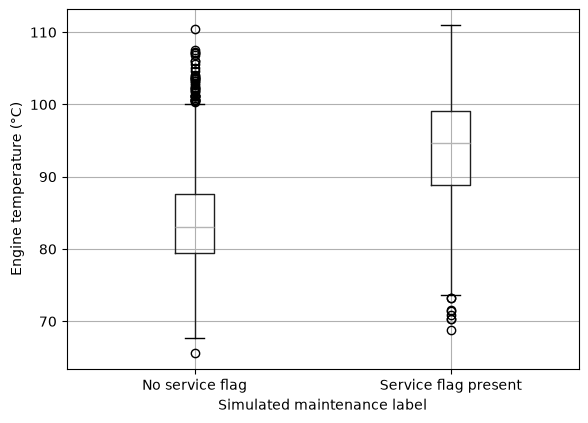

In [20]:
# Compare temperature scores across the two simulated outcome categories.
ax = visual_pd.boxplot(
    column="engine_temperature_c",
    by="service_group"
)

ax.set_title("")
plt.suptitle("")

plt.xlabel("Simulated maintenance label")
plt.ylabel("Engine temperature (°C)")

plt.savefig(
    "images/engine_temperature_by_service.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3. Fit a Spark ML classification pipeline

Retain the previous preprocessing design: index the operating-environment category, assemble the three continuous sensor measurements, and standardize the resulting feature vector. A Random Forest then predicts `maintenance_required`.

**Model inputs:** `motor_vibration_rms`, `engine_temperature_c`, and `hydraulic_pressure_bar`, in that order. The generated `operating_environment_index` is not included in the model feature vector.


In [21]:
# Import Spark ML components for feature preparation.
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, VectorAssembler, StandardScaler

In [22]:
# Restore the integrated record table as the machine-learning input.
final_data_path = "data/machine_model_records.parquet"

ml_data = spark.read.parquet(final_data_path)
print("Modelling observation count:", ml_data.count())
ml_data.show(5)

Modelling observation count: 7060
+----------+-------------+-------------------+--------------------+----------------------+---------------------+---------------------+--------------------+
|machine_id|operating_day|motor_vibration_rms|engine_temperature_c|hydraulic_pressure_bar|diagnostic_event_code|operating_environment|maintenance_required|
+----------+-------------+-------------------+--------------------+----------------------+---------------------+---------------------+--------------------+
|   EQ-0096|           10|               2.72|               87.91|                188.12|                    0|           Dry ground|                   0|
|   EQ-0004|           24|               4.93|               88.53|                172.59|                    0|           Wet ground|                   0|
|   EQ-0020|           21|               3.42|               74.22|                205.93|                    0|           Open field|                   1|
|   EQ-0117|           11|    

In [23]:
# Index environment categories; this index is not part of the assembled model features.
environment_indexer = StringIndexer(
    inputCol="operating_environment",
    outputCol="operating_environment_index",
    handleInvalid="keep"
)

In [24]:
# Preserve the same three continuous feature roles and their order.
feature_columns = [
    "motor_vibration_rms",
    "engine_temperature_c",
    "hydraulic_pressure_bar"
]

assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="unscaled_features"
)

In [25]:
# Scale model inputs by standard deviation without mean centering.
scaler = StandardScaler(
    inputCol="unscaled_features",
    outputCol="features",
    withMean=False,
    withStd=True
)

In [26]:
# Build the preprocessing-only pipeline for reference.
ml_pipeline = Pipeline(
    stages=[
        environment_indexer,
        assembler,
        scaler
    ]
)

### 3.1 Training protocol

Use the existing seeded **80/20 split of individual daily records**. Tune Random Forest `maxDepth` over **5, 10, and 15** with three-fold cross-validation and select using ROC-AUC. No model settings or feature-processing logic have been changed to accommodate the redesigned data.

**Interpretation limit:** records from the same machine can appear in both the training and test partitions. Consequently, the resulting ROC-AUC is a record-level experimental score, not evidence of performance on entirely unseen machines. A machine-level split would be a separate experiment.


In [27]:
# Import the classifier, hyperparameter search, and binary ROC-AUC evaluator.
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import BinaryClassificationEvaluator

In [28]:
# Partition observations into reproducible training and test subsets.
train_data, test_data = ml_data.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training records:", train_data.count())
print("Testing records:", test_data.count())

Training records: 5719
Testing records: 1341


In [29]:
# Initialize the seeded Random Forest with the binary service target.
rf = RandomForestClassifier(
    labelCol="maintenance_required",
    featuresCol="features",
    seed=42
)

In [30]:
# Compose feature preparation and model training in a single Spark pipeline.
full_pipeline = Pipeline(
    stages=[
        environment_indexer,
        assembler,
        scaler,
        rf
    ]
)

In [31]:
# Compare the same three depth values as the established experiment.
param_grid = (
    ParamGridBuilder()
    .addGrid(rf.maxDepth, [5, 10, 15])
    .build()
)

In [32]:
# Select models using the area under the ROC curve.
evaluator = BinaryClassificationEvaluator(
    labelCol="maintenance_required",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

In [33]:
# Run three-fold cross-validation with the configured random seed.
cross_validator = CrossValidator(
    estimator=full_pipeline,
    estimatorParamMaps=param_grid,
    evaluator=evaluator,
    numFolds=3,
    seed=42
)

In [34]:
# Fit candidate pipelines on the training partition only.
cv_model = cross_validator.fit(train_data)

26/11/04 17:24:38 WARN DAGScheduler: Broadcasting large task binary with size 1287.5 KiB
26/11/04 17:24:38 WARN DAGScheduler: Broadcasting large task binary with size 1594.7 KiB
26/11/04 17:24:38 WARN DAGScheduler: Broadcasting large task binary with size 1878.7 KiB
26/11/04 17:24:39 WARN DAGScheduler: Broadcasting large task binary with size 2.1 MiB
26/11/04 17:24:39 WARN DAGScheduler: Broadcasting large task binary with size 2.3 MiB
26/11/04 17:24:39 WARN DAGScheduler: Broadcasting large task binary with size 1260.7 KiB
26/11/04 17:24:44 WARN DAGScheduler: Broadcasting large task binary with size 1255.6 KiB
26/11/04 17:24:45 WARN DAGScheduler: Broadcasting large task binary with size 1542.5 KiB
26/11/04 17:24:45 WARN DAGScheduler: Broadcasting large task binary with size 1811.5 KiB
26/11/04 17:24:45 WARN DAGScheduler: Broadcasting large task binary with size 2046.4 KiB
26/11/04 17:24:45 WARN DAGScheduler: Broadcasting large task binary with size 2.2 MiB
26/11/04 17:24:46 WARN DAGSche

### 3.2 Inspect classification results

Once the pipeline is executed, review the predicted labels and probabilities, the confusion table, ROC-AUC, ROC curve, selected tree depth, and feature importances. The numerical results are deliberately **not prefilled**: they must be generated from the new CSV files.

Plots are written to `images/` when these cells run. The prior image files and cached model outputs have been removed because they describe the previous dataset.


In [35]:
# Prepare utilities for inspecting and saving validation graphics.
import os
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.ml.functions import vector_to_array
from pyspark.sql.functions import col

images_dir = "images"
os.makedirs(images_dir, exist_ok=True)

In [36]:
# Generate held-out predictions and review the associated probabilities.
predictions = cv_model.transform(test_data)

predictions.select(
    "machine_id",
    "operating_environment",
    "motor_vibration_rms",
    "engine_temperature_c",
    "hydraulic_pressure_bar",
    "maintenance_required",
    "prediction",
    "probability"
).show(10, truncate=False)

+----------+---------------------+-------------------+--------------------+----------------------+--------------------+----------+----------------------------------------+
|machine_id|operating_environment|motor_vibration_rms|engine_temperature_c|hydraulic_pressure_bar|maintenance_required|prediction|probability                             |
+----------+---------------------+-------------------+--------------------+----------------------+--------------------+----------+----------------------------------------+
|EQ-0000   |Rolling terrain      |2.19               |84.05               |195.78                |0                   |0.0       |[0.964260014781844,0.035739985218155926]|
|EQ-0001   |Open field           |2.84               |82.85               |214.61                |0                   |0.0       |[0.981655778411389,0.018344221588611053]|
|EQ-0002   |Wet ground           |2.92               |79.76               |178.41                |0                   |0.0       |[0.9553620

In [37]:
# Tabulate observed versus predicted service labels.
confusion_matrix = (
    predictions
    .groupBy("maintenance_required", "prediction")
    .count()
    .orderBy("maintenance_required", "prediction")
)

confusion_matrix.show()

+--------------------+----------+-----+
|maintenance_required|prediction|count|
+--------------------+----------+-----+
|                   0|       0.0|  979|
|                   0|       1.0|   55|
|                   1|       0.0|  142|
|                   1|       1.0|  165|
+--------------------+----------+-----+



/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


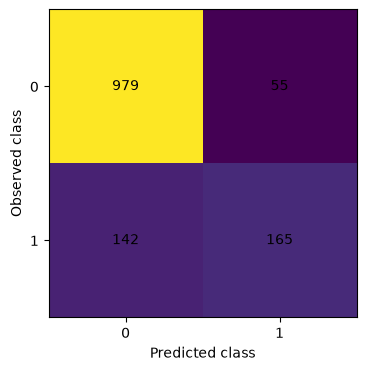

In [38]:
# Render the confusion table as a static Matplotlib heatmap.
confusion_pd = confusion_matrix.toPandas()

confusion_pivot = confusion_pd.pivot(
    index="maintenance_required",
    columns="prediction",
    values="count"
).fillna(0)

plt.figure(figsize=(5, 4))
plt.imshow(confusion_pivot.values)

plt.xticks(
    range(len(confusion_pivot.columns)),
    [str(int(x)) for x in confusion_pivot.columns]
)
plt.yticks(
    range(len(confusion_pivot.index)),
    [str(int(x)) for x in confusion_pivot.index]
)

plt.xlabel("Predicted class")
plt.ylabel("Observed class")
for i in range(confusion_pivot.shape[0]):
    for j in range(confusion_pivot.shape[1]):
        plt.text(
            j,
            i,
            int(confusion_pivot.values[i, j]),
            ha="center",
            va="center"
        )

plt.savefig(
    "images/maintenance_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [39]:
# Compute the held-out ROC-AUC with the fitted Spark evaluator.
auc = evaluator.evaluate(predictions)

print(f"Area Under ROC Curve AUC: {auc:.4f}")

Area Under ROC Curve AUC: 0.8570


/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


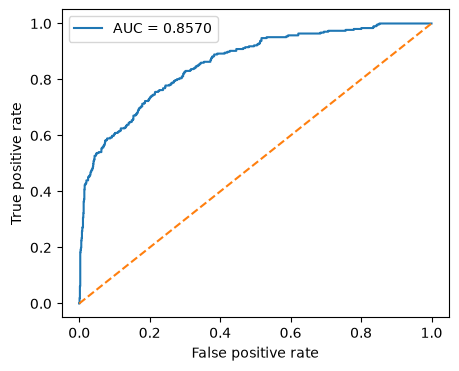

In [40]:
# Trace the ROC curve using the predicted probability of the positive class.
roc_data = (
    predictions
    .select(
        "maintenance_required",
        vector_to_array("probability")[1].alias("predicted_service_probability")
    )
    .toPandas()
)

roc_data = roc_data.sort_values(
    by="predicted_service_probability",
    ascending=False
)

total_positive = (roc_data["maintenance_required"] == 1).sum()
total_negative = (roc_data["maintenance_required"] == 0).sum()

true_positives = 0
false_positives = 0

tpr_values = [0.0]
fpr_values = [0.0]

for _, row in roc_data.iterrows():
    if row["maintenance_required"] == 1:
        true_positives += 1
    else:
        false_positives += 1

    tpr_values.append(true_positives / total_positive)
    fpr_values.append(false_positives / total_negative)

plt.figure(figsize=(5, 4))
plt.plot(fpr_values, tpr_values, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()

plt.savefig(
    "images/maintenance_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
# Inspect the winning depth and importances for the three selected inputs.
best_pipeline_model = cv_model.bestModel
best_rf_model = best_pipeline_model.stages[-1]

print("Selected Random Forest maximum depth:",
      best_rf_model.getMaxDepth())

feature_importances = best_rf_model.featureImportances.toArray()

importance_df = pd.DataFrame({
    "input_feature": feature_columns,
    "relative_importance": feature_importances
})

importance_df = importance_df.sort_values(
    by="relative_importance",
    ascending=False
)

importance_spark_df = spark.createDataFrame(importance_df)

importance_spark_df.show(truncate=False)

Selected Random Forest maximum depth: 10


/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:676: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:953: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/pyspark/sql/pandas/conversion.py:704: UserWarning: createDataFrame attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INS

+----------------------+-------------------+
|input_feature         |relative_importance|
+----------------------+-------------------+
|motor_vibration_rms   |0.5538333639023494 |
|engine_temperature_c  |0.3140078778890226 |
|hydraulic_pressure_bar|0.13215875820862782|
+----------------------+-------------------+



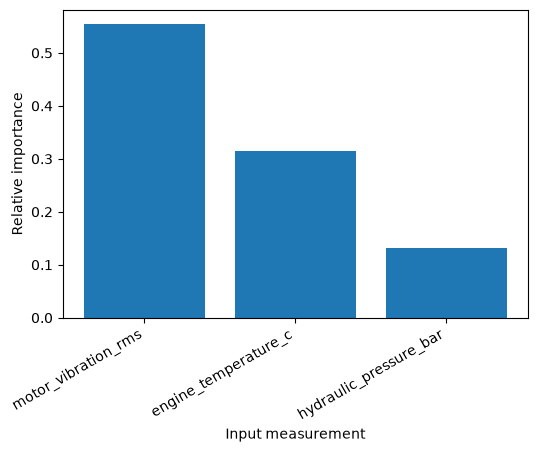

In [42]:
# Visualize the relative contribution assigned to each model input.
plt.figure(figsize=(6, 4))

plt.bar(
    importance_df["input_feature"],
    importance_df["relative_importance"]
)

plt.xlabel("Input measurement")
plt.ylabel("Relative importance")
plt.xticks(rotation=30, ha="right")

plt.savefig(
    "images/sensor_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()